# Project 2: Making handwritten letters with a GAN
We use the EMNIST Letters data. It has small images (28x28) of letters from A to Z.

In [7]:
import torch
import torch.nn as nn
import torchvision
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(torch.__version__, device)

2.14.1+cu126 cuda


## 1. Data
First we load the data and look at it.

In [8]:
data = torchvision.datasets.EMNIST("data", split="letters", train=True, download=True)

images = data.data
labels = data.targets - 1    # now 0 = A and 25 = Z
letters = "ABCDEFGHIJKLMNOPQRSTUVWXYZ"

print(images.shape)
print(labels.shape)

torch.Size([124800, 28, 28])
torch.Size([124800])


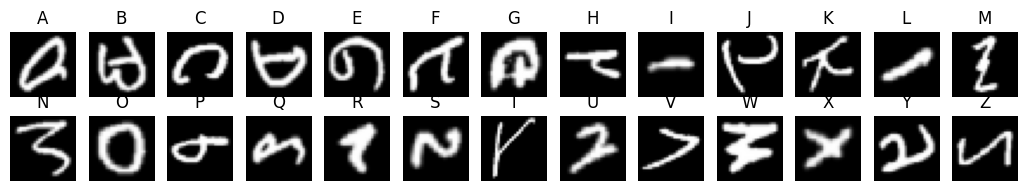

In [9]:
# show one image for each letter
plt.figure(figsize=(13, 2))
for i in range(26):
    plt.subplot(2, 13, i + 1)
    plt.imshow(images[labels == i][0], cmap="gray")
    plt.title(letters[i])
    plt.axis("off")
plt.show()

**Problem:** the letters look turned and mirrored. This is because rows and columns are swapped in the data. We swap them back.

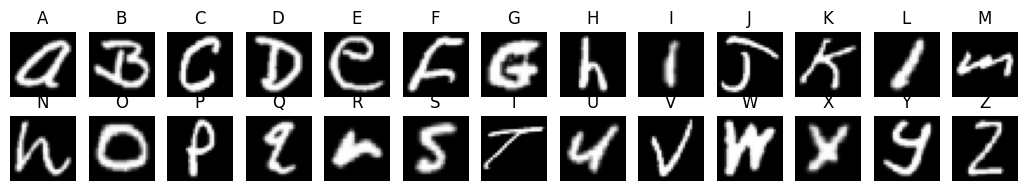

In [10]:
fixed_images = images.transpose(1, 2)    # swap rows and columns

plt.figure(figsize=(13, 2))
for i in range(26):
    plt.subplot(2, 13, i + 1)
    plt.imshow(fixed_images[labels == i][0], cmap="gray")
    plt.title(letters[i])
    plt.axis("off")
plt.show()

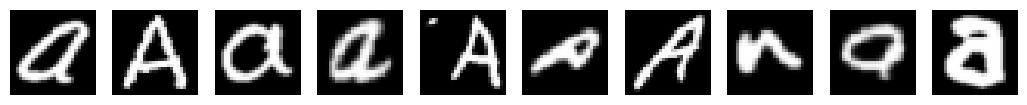

In [11]:
# show 10 different A images
a_images = fixed_images[labels == 0]

plt.figure(figsize=(13, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(a_images[i], cmap="gray")
    plt.axis("off")
plt.show()